In [39]:
import tskit
import pandas as pd
from lets_plot import *
import matplotlib
LetsPlot.setup_html()

chromosome = 14

In [2]:
import os
os.getcwd()

'/home/jobste/Relate'

In [4]:
original = tskit.load("All_snps_with_outgroup_info/Chr1.trees")
remappedTs = tskit.load("Remapped_newNe/Chr1.trees")

In [6]:
chrSample = pd.read_table("All_snps_with_outgroup_info_newAA/Chr" + str(chromosome) + "_relate.sample")


# %%
meta = pd.read_csv("TsinferMetaData_Vcf.txt")
meta.head()

sampleMeta = chrSample.merge(meta, how = "left", left_on = "ID_1", right_on = "ID")
sampleMeta = sampleMeta.iloc[1: , :]

complex_schema = tskit.MetadataSchema({
    'codec': 'json',
    'additionalProperties': False,
    'properties': {'name': {'description': 'ENA accession number',
                                 'type': 'string'},
                   'pop': {'description': 'Lineage',
                           'type': 'string'},
                    'subpop': {'description': 'Subspecies',
                           'type': 'string'}},
    'required': ['name', 'pop', 'subpop'],
    'type': 'object',
})

complex_schema_pop = tskit.MetadataSchema({
    'codec': 'json',
    'additionalProperties': False,
    'properties': {'pop': {'description': 'Lineage',
                           'type': 'string'}},
    'required': ['pop'],
    'type': 'object',
})



# Add meta data

remappedTables = remappedTs.dump_tables()
remappedTables.individuals.metadata_schema = complex_schema
remappedTables.populations.metadata_schema = complex_schema_pop



# Add metadata
metadata_column = [{"name": list(sampleMeta.ID_1)[ind], "pop": list(sampleMeta.Pop)[ind], "subpop": list(sampleMeta.SubPop)[ind]} for ind in range(remappedTs.num_individuals)]
encoded_metadata_column = [
    remappedTables.individuals.metadata_schema.validate_and_encode_row(r) for r in metadata_column
]
md, md_offset = tskit.pack_bytes(encoded_metadata_column)
remappedTables.individuals.set_columns(flags=range(remappedTs.num_individuals), metadata=md, metadata_offset=md_offset)




In [7]:
meta[["Pop", "SubPop"]].drop_duplicates()

,Pop,SubPop
0,C,Carnica
2,C,Buckfast
5,M,Mellifera
149,H,Admixed
176,A,Capensis
177,A,Scutellata
399,U,France
787,C,Ligustica
820,M,Iberiensis
852,U,Denmark


In [10]:
# Add data to population table
popdata_column = [{"pop": x} for x in set(meta.Pop)]
encoded_popdata_column = [
    remappedTables.populations.metadata_schema.validate_and_encode_row(r) for r in popdata_column
]
md, md_offset = tskit.pack_bytes(encoded_popdata_column)
remappedTables.populations.set_columns(metadata=md, metadata_offset=md_offset)





In [13]:
popDict = {y: x for x,y in enumerate(set(meta.Pop))}
ind_nodes = list([x.id for x in remappedTs.individuals()])
ind_pops = [popDict[sampleMeta.Pop.to_list()[x]] for x in ind_nodes]
indNodePopR = remappedTables.nodes.population
indNodePopR[ind_nodes] = ind_pops
remappedTables.nodes.population = indNodePopR

In [14]:
remappedTs_meta = remappedTables.tree_sequence()

In [16]:
remappedTs_meta.divergence(sample_sets = [remappedTs_meta.samples(3), remappedTs_meta.samples(5)])

0.0048157616150648576

In [15]:
list(remappedTs_meta.populations())

[Population(id=0, metadata={'pop': 'A'}),
 Population(id=1, metadata={'pop': 'U'}),
 Population(id=2, metadata={'pop': 'C'}),
 Population(id=3, metadata={'pop': 'H'}),
 Population(id=4, metadata={'pop': 'O'}),
 Population(id=5, metadata={'pop': 'M'})]

In [ ]:
import os
os.getcwd()

'/home/jobste/Relate'

In [22]:
sample_nodes = [remappedTs_meta.node(n) for n in remappedTs_meta.samples()]
sample_ids = [n.id for n in sample_nodes]
sample_names = [
    remappedTs_meta.individual(n).metadata["name"]
    for n in sample_ids
]
sample_pops = [
    remappedTs_meta.individual(n).metadata["pop"]
    for n in sample_ids
]
sample_subpops = [
    remappedTs_meta.individual(n).metadata["subpop"]
    for n in sample_ids
]

pops = dict()
for (node, pop) in zip(sample_ids, sample_pops):
    if not pop in pops.keys():
        pops[pop] = [node]
    else:
        pops[pop].append(node)

subpops = dict()
for (node, subpop) in zip(sample_ids, sample_subpops):
    if not subpop in subpops.keys():
        subpops[subpop] = [node]
    else:
        subpops[subpop].append(node)
numPops = len(pops.keys())

In [20]:
popsTajimaR = pd.DataFrame()
for pop in pops.keys():
    tmp = remappedTs_meta.Tajimas_D(sample_sets=pops[pop],)
    tmpDF = pd.DataFrame({"TajimaD": [tmp], "Pop": pop})
    popsTajimaR = pd.concat([popsTajimaR, tmpDF])

KeyboardInterrupt: 

In [ ]:
popsTajimaR.loc[:, "Method"] = "Remapped"
tajima = pd.concat([popsTajima, popsTajimaR])

In [ ]:
LetsPlot.setup_html()
ggplot(data = tajima) + geom_bar(aes(x = "Pop", y = "TajimaD", fill = "Method"), stat="identity", position = "dodge") + \
ggtitle("Tajima'sD, Chr1 ")

In [11]:
mu = 3.4e-9
branch_afs = mu * remappedTs.allele_frequency_spectrum(sample_sets = [pops["C"]], mode='branch')
site_afs = remappedTs.allele_frequency_spectrum(sample_sets = [pops["C"]], mode='site')


/tmp/ipykernel_1210812/3182864830.py:2: RuntimeWarning: divide by zero encountered in log10
  matplotlib.pyplot.scatter(np.arange(branch_afs_old.size), np.log10(branch_afs_old), c='black')
/tmp/ipykernel_1210812/3182864830.py:3: RuntimeWarning: divide by zero encountered in log10
  matplotlib.pyplot.scatter(np.arange(site_afs_old.size), np.log10(site_afs_old), c='grey')
/tmp/ipykernel_1210812/3182864830.py:4: RuntimeWarning: divide by zero encountered in log10
  matplotlib.pyplot.scatter(np.arange(branch_afs.size), np.log10(branch_afs), c='blue')
/tmp/ipykernel_1210812/3182864830.py:5: RuntimeWarning: divide by zero encountered in log10
  matplotlib.pyplot.scatter(np.arange(site_afs.size), np.log10(site_afs), c='green')


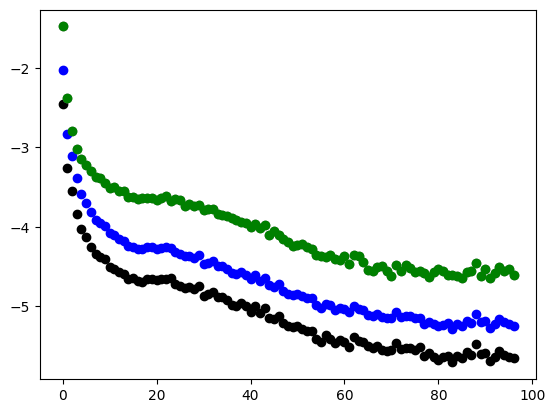

In [12]:
import numpy as np
matplotlib.pyplot.scatter(np.arange(branch_afs_old.size), np.log10(branch_afs_old), c='black')
matplotlib.pyplot.scatter(np.arange(site_afs_old.size), np.log10(site_afs_old), c='grey')
matplotlib.pyplot.scatter(np.arange(branch_afs.size), np.log10(branch_afs), c='blue')
matplotlib.pyplot.scatter(np.arange(site_afs.size), np.log10(site_afs), c='green')


In [13]:
from collections import defaultdict
mu = 3.4e-9
sfsBranch = pd.DataFrame()
sfsSite = pd.DataFrame()
for lineage in ["A", "C", "M", "O"]:
    tmpBranch =  mu * remappedTs.allele_frequency_spectrum(sample_sets = [pops[lineage]], mode='branch')
    tmpBranchDF = pd.DataFrame({"Count": range(len(tmpBranch)), "Ne": 600000,"Freq": tmpBranch})
    tmpBranchDF.loc[:, "Pop"] = lineage
    sfsBranch = pd.concat([sfsBranch, tmpBranchDF])
    tmpSite = remappedTs.allele_frequency_spectrum(sample_sets = [pops[lineage]], mode='site')
    tmpSiteDF = pd.DataFrame({"Count": range(len(tmpSite)),"Ne": 600000, "Freq": tmpSite})
    tmpSiteDF.loc[:, "Pop"] = lineage
    sfsSite = pd.concat([sfsSite, tmpSiteDF])
    tmpBranch =  mu * remappedTs_old.allele_frequency_spectrum(sample_sets = [pops[lineage]], mode='branch')
    tmpBranchDF = pd.DataFrame({"Count": range(len(tmpBranch)), "Ne": 200000, "Freq": tmpBranch})
    tmpBranchDF.loc[:, "Pop"] = lineage
    sfsBranch = pd.concat([sfsBranch, tmpBranchDF])
    tmpSite = remappedTs_old.allele_frequency_spectrum(sample_sets = [pops[lineage]], mode='site')
    tmpSiteDF = pd.DataFrame({"Count": range(len(tmpSite)), "Ne":200000, "Freq": tmpSite})
    tmpSiteDF.loc[:, "Pop"] = lineage
    sfsSite = pd.concat([sfsSite, tmpSiteDF])
sfsSite.loc[:, "Method"] = "Site"
sfsBranch.loc[:, "Method"] = "Branch"

sfsDF = pd.concat([sfsSite, sfsBranch])
sfsDF.loc[:, "LogFreq"] = np.log10(sfsDF.Freq)

/home/jobste/bin/anaconda3/envs/tsinfer/lib/python3.9/site-packages/pandas/core/arraylike.py:399: RuntimeWarning: divide by zero encountered in log10
  result = getattr(ufunc, method)(*inputs, **kwargs)


In [14]:
sfsDF.loc[:, "Method_Ne"] = sfsDF.Method + sfsDF.Ne.astype(str) 
sfsDF.head()

,Count,Ne,Freq,Pop,Method,LogFreq,Method_Ne
0,0,600000,0.025702,A,Site,-1.590036,Site600000
1,1,600000,0.000715,A,Site,-3.145722,Site600000
2,2,600000,0.000789,A,Site,-3.103161,Site600000
3,3,600000,0.001771,A,Site,-2.751750,Site600000
4,4,600000,0.003719,A,Site,-2.429595,Site600000


In [ ]:
from collections import defaultdict
mu = 3.4e-9
sfsBranch = pd.DataFrame()
sfsSite = pd.DataFrame()
for lineage in ["A", "C", "M", "O"]:
    tmpBranch =  mu * remappedTs.allele_frequency_spectrum(sample_sets = [pops[lineage]], mode='branch')
    tmpBranchDF = pd.DataFrame({"Count": range(len(tmpBranch)), "Ne": 600000,"Freq": tmpBranch})
    tmpBranchDF.loc[:, "Pop"] = lineage
    sfsBranch = pd.concat([sfsBranch, tmpBranchDF])
    tmpSite = remappedTs.allele_frequency_spectrum(sample_sets = [pops[lineage]], mode='site')
    tmpSiteDF = pd.DataFrame({"Count": range(len(tmpSite)),"Ne": 600000, "Freq": tmpSite})
    tmpSiteDF.loc[:, "Pop"] = lineage
    sfsSite = pd.concat([sfsSite, tmpSiteDF])
    tmpBranch =  mu * remappedTs_old.allele_frequency_spectrum(sample_sets = [pops[lineage]], mode='branch')
    tmpBranchDF = pd.DataFrame({"Count": range(len(tmpBranch)), "Ne": 200000, "Freq": tmpBranch})
    tmpBranchDF.loc[:, "Pop"] = lineage
    sfsBranch = pd.concat([sfsBranch, tmpBranchDF])
    tmpSite = remappedTs_old.allele_frequency_spectrum(sample_sets = [pops[lineage]], mode='site')
    tmpSiteDF = pd.DataFrame({"Count": range(len(tmpSite)), "Ne":200000, "Freq": tmpSite})
    tmpSiteDF.loc[:, "Pop"] = lineage
    sfsSite = pd.concat([sfsSite, tmpSiteDF])
sfsSite.loc[:, "Method"] = "Site"
sfsBranch.loc[:, "Method"] = "Branch"

sfsDF = pd.concat([sfsSite, sfsBranch])
sfsDF.loc[:, "LogFreq"] = np.log10(sfsDF.Freq)

/home/jobste/bin/anaconda3/envs/tsinfer/lib/python3.9/site-packages/pandas/core/arraylike.py:399: RuntimeWarning: divide by zero encountered in log10
  result = getattr(ufunc, method)(*inputs, **kwargs)


In [15]:
ggplot(data = sfsDF) + geom_point(aes(x = "Count", y = "LogFreq", colour = "Method_Ne"), stat="identity", position = "dodge") + \
facet_wrap(facets = "Pop", scales = "free")

In [50]:

#Subsepcies
mu = 3.4e-9
sfsBranch_sub = pd.DataFrame()
sfsSite_sub = pd.DataFrame()
for subpop in ["Capensis", "Scutellata", "Unicolor", "Carnica", "Ligustica","Mellifera", "Iberiensis", "Caucasia"]:
    print(subpop)
    tmpBranch =  mu * remappedTs.allele_frequency_spectrum(sample_sets = [subpops[subpop]], mode='branch', polarised = True)
    tmpBranchDF = pd.DataFrame({"Count": range(len(tmpBranch)), "Ne": 600000,"Freq": tmpBranch})
    tmpBranchDF.loc[:, "Pop"] = subpop
    sfsBranch_sub = pd.concat([sfsBranch_sub, tmpBranchDF])
    tmpSite = remappedTs.allele_frequency_spectrum(sample_sets = [subpops[subpop]], mode='site', polarised = True)
    tmpSiteDF = pd.DataFrame({"Count": range(len(tmpSite)),"Ne": 600000, "Freq": tmpSite})
    tmpSiteDF.loc[:, "Pop"] = subpop
    sfsSite_sub = pd.concat([sfsSite_sub, tmpSiteDF])





Capensis
Scutellata
Unicolor
Carnica
Ligustica
Mellifera
Iberiensis
Caucasia


In [51]:
import numpy as np
sfsSite_sub.loc[:, "Method"] = "Site"
sfsBranch_sub.loc[:, "Method"] = "Branch"

sfsDF_sub = pd.concat([sfsSite_sub, sfsBranch_sub])
sfsDF_sub.loc[:, "LogFreq"] = np.log(sfsDF_sub.Freq)


In [52]:
ggplot(data = sfsDF_sub) + geom_point(aes(x = "Count", y = "LogFreq", colour = "Method"), stat="identity", position = "dodge") + \
facet_wrap(facets = "Pop", scales = "free_x")

In [ ]:
sfsDF.loc[:, "LogFreq"] = np.log10(sfsDF.Freq)

In [17]:
segsitesDF.loc[:, "Method_Ne"] = segsitesDF.Method + segsitesDF.Ne.astype(str) 

In [21]:
ggplot() + geom_point(aes(x = "Lineage", y = "SegSites", color = "Method_Ne"), data = segsitesDF) + \
scale_color_manual(values = ["red", "black", "blue", "pink"]) + ggtitle("Segregating sites, Chr1")

In [25]:

mu = 3.4e-9
diversityBranch = pd.DataFrame()
diversitySite = pd.DataFrame()
for lineage in ["A", "C", "M", "O"]:
    tmpBranchDF = pd.DataFrame({"Lineage": lineage, "Ne": 600000, "Diversity": mu * remappedTs.diversity(sample_sets = [pops[lineage]], mode='branch')})
    diversityBranch = pd.concat([diversityBranch, tmpBranchDF])
    tmpSiteDF = pd.DataFrame({"Lineage": lineage, "Ne": 600000, "Diversity": remappedTs.diversity(sample_sets = [pops[lineage]], mode='site')})
    diversitySite = pd.concat([diversitySite, tmpSiteDF])
    tmpBranchDF = pd.DataFrame({"Lineage": lineage, "Ne": 200000, "Diversity": mu * remappedTs_old.diversity(sample_sets = [pops[lineage]], mode='branch')})
    diversityBranch = pd.concat([diversityBranch, tmpBranchDF])
    tmpSiteDF = pd.DataFrame({"Lineage": lineage, "Ne": 200000, "Diversity": remappedTs_old.diversity(sample_sets = [pops[lineage]], mode='site')})
    diversitySite = pd.concat([diversitySite, tmpSiteDF])


diversitySite.loc[:, "Method"] = "Site"
diversityBranch.loc[:, "Method"] = "Branch"

diversityDF = pd.concat([diversitySite, diversityBranch])

In [26]:
diversityDF.loc[:, "Method_Ne"] = diversityDF.Method + diversityDF.Ne.astype(str) 

In [27]:
ggplot() + geom_point(aes(x = "Lineage", y = "Diversity", color = "Method_Ne"), data = diversityDF) + \
scale_color_manual(values = ["red", "black", "blue", "pink"]) 